In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

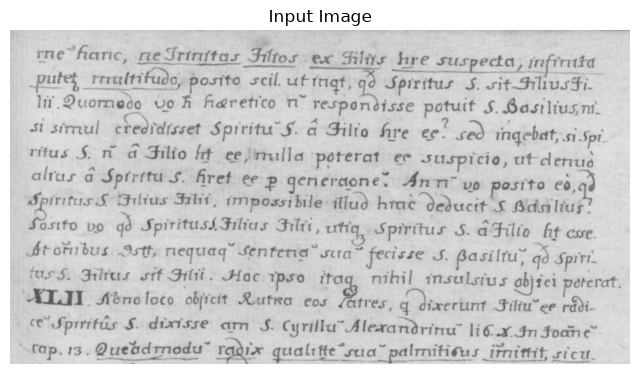

In [2]:
# Change the path to whichever image you want to sharpen
image = cv2.imread("Test.jpeg", cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Image not found. Check the file path.")

plt.figure(figsize=(8, 6))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Input Image")
plt.axis("off")
plt.show()

In [3]:
def sharpen_unsharp(image, strength=1.5, sigma=1.0):
    smooth = cv2.GaussianBlur(image, (0, 0), sigma)

    sharpened = cv2.addWeighted(
        image, 1 + strength,
        smooth, -strength, 0
    )

    return sharpened

In [4]:
def sharpen_laplacian(image, strength=0.5):
    laplacian = cv2.Laplacian(image, cv2.CV_32F)

    sharpened = (
        image.astype(np.float32) - strength * laplacian
    )

    return np.uint8(np.clip(sharpened, 0, 255))

In [5]:
def sharpen_clahe(image):
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(image)

    return sharpen_unsharp(
        enhanced,
        strength=1.5,
        sigma=1.0
    )

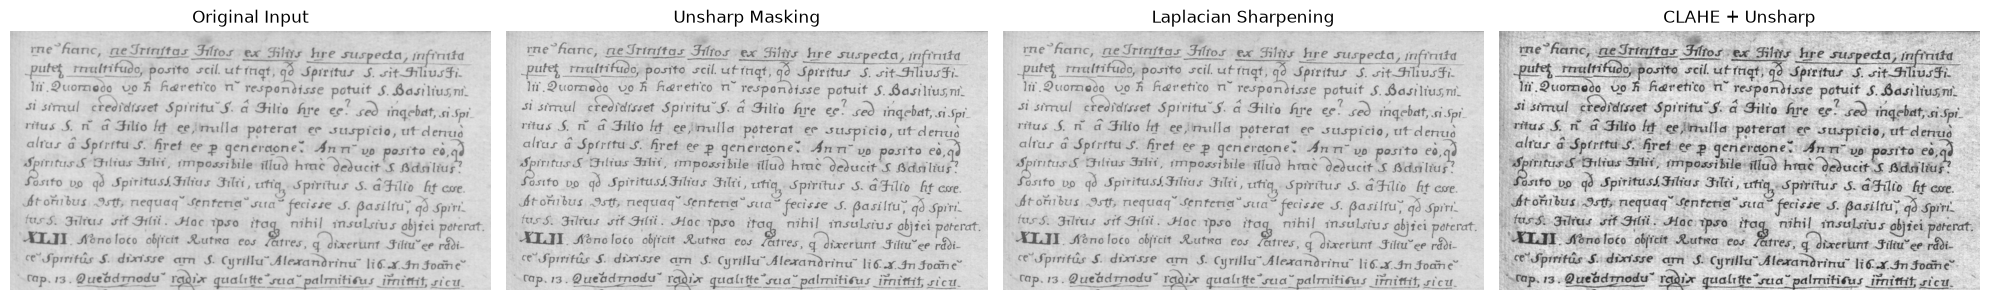

In [6]:
unsharp = sharpen_unsharp(image)
laplacian = sharpen_laplacian(image)
clahe = sharpen_clahe(image)

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

images = [image, unsharp, laplacian, clahe]
titles = [
    "Original Input",
    "Unsharp Masking",
    "Laplacian Sharpening",
    "CLAHE + Unsharp"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Set this to the path of the clean reference, if available
reference_path = "Test.jpeg"

if reference_path is not None:
    original = cv2.imread(
        reference_path,
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        raise FileNotFoundError("Reference image not found.")

    if original.shape != image.shape:
        raise ValueError("Reference and input must have the same dimensions.")

    results = {
        "Input": image,
        "Unsharp Masking": unsharp,
        "Laplacian": laplacian,
        "CLAHE + Unsharp": clahe
    }

    for name, result in results.items():
        psnr = cv2.PSNR(original, result)
        print(f"{name}: {psnr:.2f} dB")
else:
    print("No clean reference available. Compare readability visually.")

Input: 361.20 dB
Unsharp Masking: 33.50 dB
Laplacian: 34.72 dB
CLAHE + Unsharp: 21.14 dB


In [22]:
original = image.copy()

blurred = cv2.GaussianBlur(
    original, (0, 0), sigmaX=2
)

results = {
    "Blurred": blurred,
    "Unsharp": sharpen_unsharp(blurred),
    "Laplacian": sharpen_laplacian(blurred),
    "CLAHE": sharpen_clahe(blurred)
}

for name, result in results.items():
    print(f"{name}: {cv2.PSNR(original, result):.2f} dB")

Blurred: 29.24 dB
Unsharp: 30.94 dB
Laplacian: 30.42 dB
CLAHE: 20.83 dB


In [17]:
def enhance_text(image, method="unsharp"):
    if method == "unsharp":
        return sharpen_unsharp(image)

    elif method == "laplacian":
        return sharpen_laplacian(image)

    elif method == "clahe":
        return sharpen_clahe(image)

    else:
        raise ValueError("Unknown sharpening method")

In [18]:
def detect_blur(image, threshold=100):
    gray = image

    # Calculate Laplacian variance
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    score = laplacian.var()

    # Lower scores suggest more blur
    is_blurred = score < threshold

    return is_blurred, score

In [19]:
def auto_enhance(image, threshold=100, method="unsharp"):

    is_blurred, score = detect_blur(image, threshold)

    print(f"Blur score: {score:.2f}")

    if is_blurred:
        print("Possible blur detected. Applying sharpening.")
        result = enhance_text(image, method=method)
    else:
        print("Image appears sufficiently sharp. No sharpening applied.")
        result = image.copy()

    return result

Blur score: 87.23
Possible blur detected. Applying sharpening.


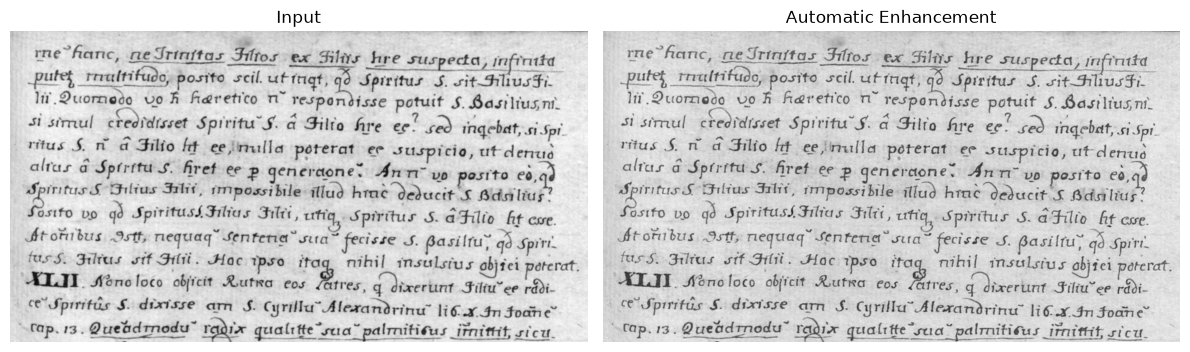

In [20]:
result = auto_enhance(
    image,
    threshold=100,
    method="unsharp"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Input")

axes[1].imshow(result, cmap="gray")
axes[1].set_title("Automatic Enhancement")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
for sigma in [0, 1, 2, 3, 4, 5]:

    if sigma == 0:
        test = image.copy()
    else:
        test = cv2.GaussianBlur(
            image, (0, 0), sigmaX=sigma
        )

    is_blurred, score = detect_blur(test, threshold=40)

    print(
        f"Sigma {sigma}: "
        f"Score={score:.2f}, "
        f"Blurred={is_blurred}"
    )

Sigma 0: Score=87.23, Blurred=False
Sigma 1: Score=29.32, Blurred=True
Sigma 2: Score=8.31, Blurred=True
Sigma 3: Score=3.31, Blurred=True
Sigma 4: Score=2.02, Blurred=True
Sigma 5: Score=1.64, Blurred=True


In [26]:
image2 = cv2.imread("test2.png", cv2.IMREAD_GRAYSCALE)

for sigma in [0, 1, 2, 3, 4, 5]:
    if sigma == 0:
        test = image2.copy()
    else:
        test = cv2.GaussianBlur(image2, (0, 0), sigma)

    is_blurred, score = detect_blur(test, threshold=40)

    print(f"Sigma {sigma}: Score={score:.2f}, Blurred={is_blurred}")

Sigma 0: Score=5488.44, Blurred=False
Sigma 1: Score=364.56, Blurred=False
Sigma 2: Score=30.13, Blurred=True
Sigma 3: Score=4.89, Blurred=True
Sigma 4: Score=2.50, Blurred=True
Sigma 5: Score=2.02, Blurred=True


In [29]:
# Load both manuscripts
images = {
    "Manuscript 1": cv2.imread("Test.jpeg", cv2.IMREAD_GRAYSCALE),
    "Manuscript 2": cv2.imread("test2.png", cv2.IMREAD_GRAYSCALE)
}

# Create motion blur
def create_motion_blur(image, length=15):
    kernel = np.zeros((length, length))
    kernel[length // 2, :] = 1
    kernel /= kernel.sum()
    return cv2.filter2D(image, -1, kernel)

# Create defocus blur
def create_defocus_blur(image, radius=5):
    size = 2 * radius + 1
    kernel = np.zeros((size, size), np.float32)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)
    kernel /= kernel.sum()
    return cv2.filter2D(image, -1, kernel)

# Test both blur types
for name, img in images.items():
    if img is None:
        print(f"Could not load {name}")
        continue

    print(f"\n{name}")

    for length in [5, 10, 15, 20]:
        blurred = create_motion_blur(img, length)
        detected, score = detect_blur(blurred, threshold=40)

        print(f"Motion length {length}: Score={score:.2f}, Detected={detected}")

    for radius in [2, 3, 5, 7]:
        blurred = create_defocus_blur(img, radius)
        detected, score = detect_blur(blurred, threshold=40)

        print(f"Defocus radius {radius}: Score={score:.2f}, Detected={detected}")


Manuscript 1
Motion length 5: Score=41.26, Detected=False
Motion length 10: Score=24.75, Detected=True
Motion length 15: Score=19.04, Detected=True
Motion length 20: Score=16.29, Detected=True
Defocus radius 2: Score=26.51, Detected=True
Defocus radius 3: Score=12.74, Detected=True
Defocus radius 5: Score=4.16, Detected=True
Defocus radius 7: Score=2.37, Detected=True

Manuscript 2
Motion length 5: Score=888.32, Detected=False
Motion length 10: Score=454.52, Detected=False
Motion length 15: Score=341.38, Detected=False
Motion length 20: Score=288.49, Detected=False
Defocus radius 2: Score=341.86, Detected=False
Defocus radius 3: Score=93.77, Detected=False
Defocus radius 5: Score=18.80, Detected=True
Defocus radius 7: Score=8.78, Detected=True


In [30]:
def detect_blur_percentage(image, sigma=1):
    # Original Laplacian variance
    original_score = cv2.Laplacian(
        image, cv2.CV_64F
    ).var()

    # Apply additional Gaussian blur
    blurred = cv2.GaussianBlur(
        image, (0, 0), sigmaX=sigma
    )

    # New Laplacian variance
    blurred_score = cv2.Laplacian(
        blurred, cv2.CV_64F
    ).var()

    # Calculate percentage reduction
    reduction = (
        (original_score - blurred_score)
        / max(original_score, 1e-10)
    ) * 100

    return reduction, original_score, blurred_score

In [31]:
for name, img in images.items():

    print(f"\n{name}")

    for sigma in [0, 1, 2, 3, 4, 5]:

        if sigma == 0:
            test = img.copy()
        else:
            test = cv2.GaussianBlur(
                img, (0, 0), sigmaX=sigma
            )

        reduction, before, after = detect_blur_percentage(test)

        print(
            f"Sigma {sigma}: "
            f"Reduction={reduction:.2f}%"
        )


Manuscript 1
Sigma 0: Reduction=66.39%
Sigma 1: Reduction=42.05%
Sigma 2: Reduction=22.40%
Sigma 3: Reduction=9.54%
Sigma 4: Reduction=3.99%
Sigma 5: Reduction=0.51%

Manuscript 2
Sigma 0: Reduction=93.36%
Sigma 1: Reduction=67.36%
Sigma 2: Reduction=40.91%
Sigma 3: Reduction=16.71%
Sigma 4: Reduction=5.66%
Sigma 5: Reduction=3.98%


In [33]:
for name, img in images.items():
    print(f"\n{name}")

    for length in [5, 10, 15, 20]:
        test = create_motion_blur(img, length)
        reduction, _, _ = detect_blur_percentage(test)

        print(f"Motion {length}: Reduction={reduction:.2f}%")

    for radius in [2, 3, 5, 7]:
        test = create_defocus_blur(img, radius)
        reduction, _, _ = detect_blur_percentage(test)

        print(f"Defocus {radius}: Reduction={reduction:.2f}%")


Manuscript 1
Motion 5: Reduction=56.54%
Motion 10: Reduction=57.90%
Motion 15: Reduction=57.79%
Motion 20: Reduction=56.99%
Defocus 2: Reduction=40.06%
Defocus 3: Reduction=28.40%
Defocus 5: Reduction=16.13%
Defocus 7: Reduction=9.06%

Manuscript 2
Motion 5: Reduction=84.53%
Motion 10: Reduction=82.04%
Motion 15: Reduction=80.40%
Motion 20: Reduction=79.15%
Defocus 2: Reduction=70.47%
Defocus 3: Reduction=65.18%
Defocus 5: Reduction=63.90%
Defocus 7: Reduction=53.86%


In [34]:
def process_image(image, mode="auto"):
    if mode == "always":
        return sharpen_unsharp(image)

    elif mode == "never":
        return image.copy()

    elif mode == "auto":
        reduction, _, _ = detect_blur_percentage(image)

        if reduction < 45:
            return sharpen_unsharp(image)

        return image.copy()

    else:
        raise ValueError("Mode must be auto, always, or never")